In [2]:
import numpy as np
import time
import seaborn as sns
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup
from IPython.display import Markdown, display,IFrame,HTML,Image
import itertools
from z3 import *
from math import gcd
from functools import lru_cache
from scipy.ndimage import label,sum_labels
from matplotlib.patches import Rectangle

C:\Users\g\anaconda3\lib\site-packages\urllib3\connectionpool.py:1061: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.janestreet.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/1.26.x/advanced-usage.html#ssl-warnings
  warnings.warn(


### Puzzle as published 
https://www.janestreet.com/puzzles/hooks-11-index/

### Hooks 11

The grid above can be partitioned into 9 L-shaped “hooks”. The largest is 9-by-9 (contains 17 squares), the next largest is 8-by-8 (contains 15 squares), and so on. The smallest hook is just a single square. Find where the hooks are located, and place nine 9’s in one of the hooks, eight 8’s in another, seven 7’s in another, and so on.
The filled squares must form a connected region. (Squares are “connected” if they are orthogonally adjacent.) Furthermore, every 2-by-2 region must contain at least one unfilled square.
The set of filled squares must be decomposable into
9 distinct pentominos
, with no repeated shapes (including reflection or rotation). Finally, the sum of the of the values in each pentomino must be a multiple of 5.
A value
outside
the grid denotes the either first number or pentomino

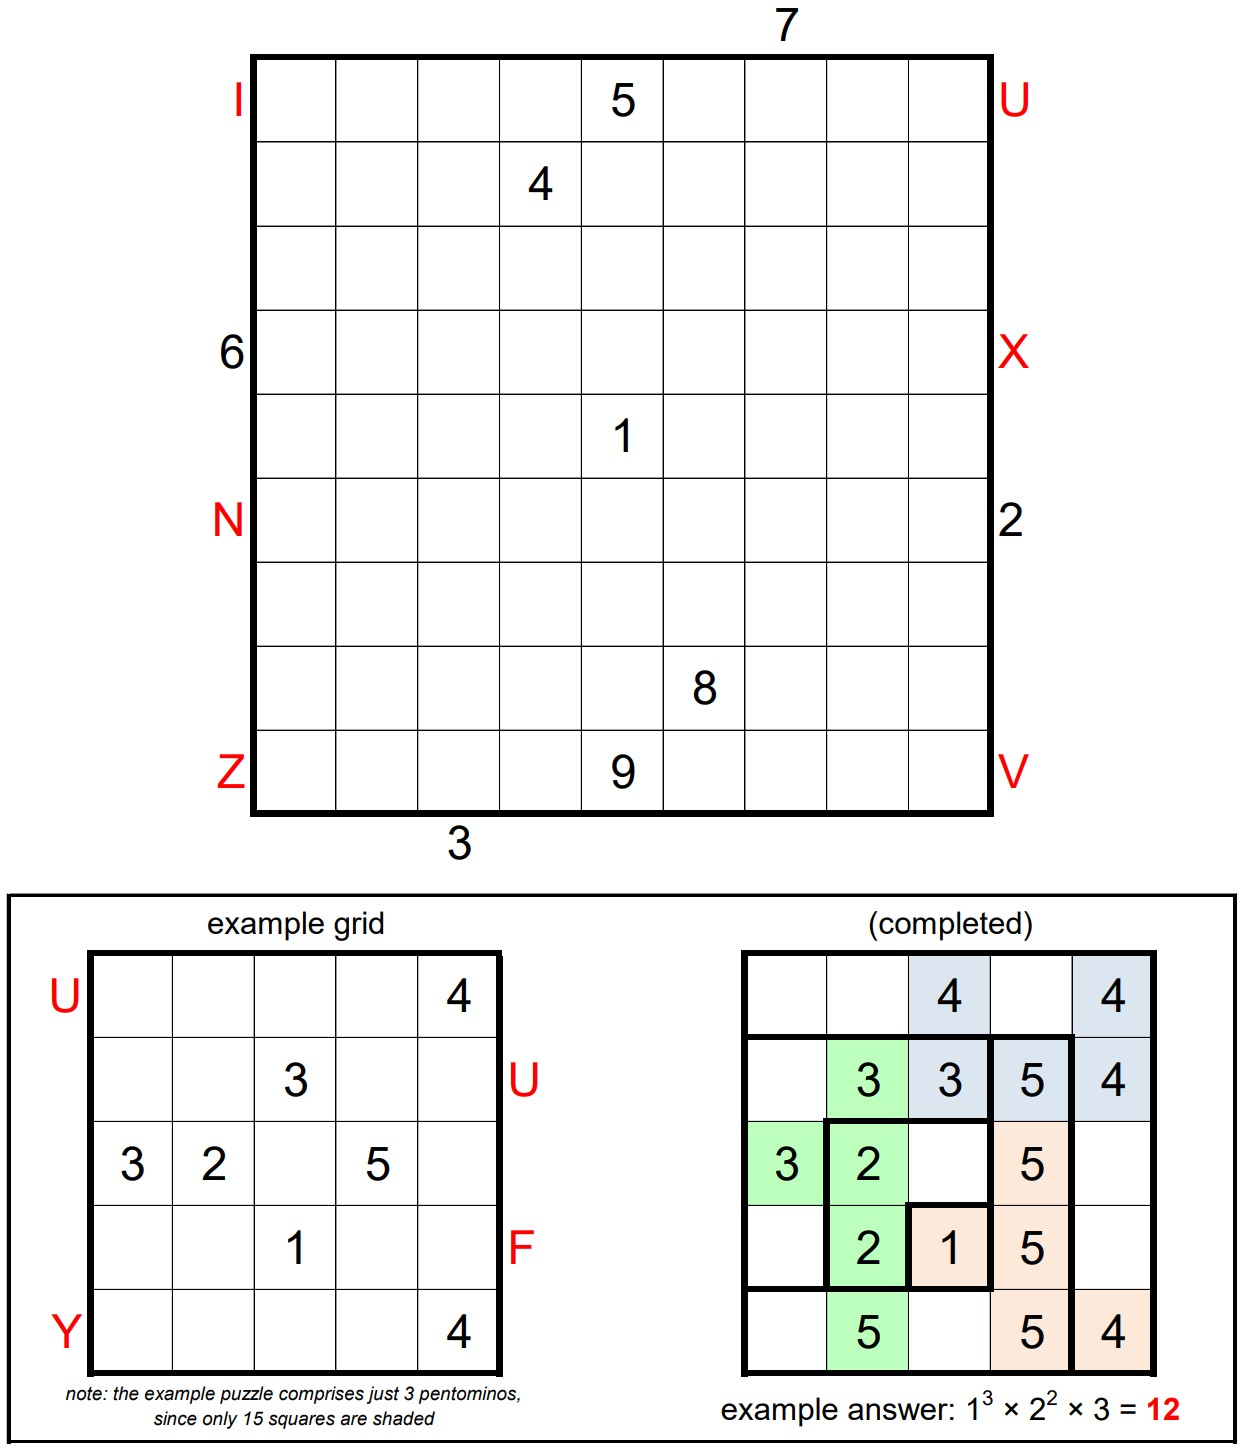

In [2]:
url='https://www.janestreet.com/puzzles/hooks-11-index/'
res = requests.get(url,verify=False)
soup = BeautifulSoup(res.content, 'html.parser')
display(Markdown('### Puzzle as published \n'+url))
y =[text for text in soup.body.stripped_strings]
#display([(i,j) for i,j in enumerate(y)])
display(Markdown("### "+y[13]+"\n\n"+str("\n".join(y[15:23]))))
display(Image('https://www.janestreet.com/puzzles/hooks-11.jpg',width=400))

In [3]:
example=np.array([[-1,-1,-1,-1, 4],
                  [-1,-1, 3,-1,-1],
                  [ 3, 2,-1, 5,-1],
                  [-1,-1, 1,-1,-1],
                  [-1,-1,-1,-1, 4]])




full=np.array([[-1, -1, -1, -1,  5, -1, -1, -1, -1],
               [-1, -1, -1,  4, -1, -1, -1, -1, -1],
               [-1, -1, -1, -1, -1, -1, -1, -1, -1],
               [-1, -1, -1, -1, -1, -1, -1, -1, -1],
               [-1, -1, -1, -1,  1, -1, -1, -1, -1],
               [-1, -1, -1, -1, -1, -1, -1, -1, -1],
               [-1, -1, -1, -1, -1, -1, -1, -1, -1],
               [-1, -1, -1, -1, -1,  8, -1, -1, -1],
               [-1, -1, -1, -1,  9, -1, -1, -1, -1]])



np.unique(full,return_counts=True)

(array([-1,  1,  4,  5,  8,  9]), array([76,  1,  1,  1,  1,  1], dtype=int64))

In [4]:
def grid_print(solved,matrix):
    N= solved.shape[0]
    fig,ax = plt.subplots(1,1,figsize=(N/2,N/2))
    x = np.array((solved*matrix).astype('int').astype('str'))
    x[x=="0"] ="-"
    ax = sns.heatmap(matrix,annot=x,cbar=False,cmap="tab10",fmt="",linewidths=0.25,
                     annot_kws={"fontsize":12})
    ax.tick_params(left=False, bottom=False,labelleft=True, labelright=False,labeltop=True,labelbottom=False)
    plt.axis("off")
    plt.tight_layout()
    plt.show()
    
def neigh(x,y,N):
    return [(i+x,j+y) for i,j in [(-1,0),(0,-1),(1,0),(0,1)] if i+x >=0 and i+x <N and j+y >=0 and j+y <N]

def areas(grid):
    labels, num = label(np.logical_not(grid!=0))
    areas = sum_labels(np.logical_not(grid!=0), labels, index=range(1, num+1))
    print(areas)
    return np.prod(areas)

In [5]:
def reset(positions):
    min_x, min_y = min(positions, key=lambda x:x[::-1])
    return tuple(sorted((x-min_x, y-min_y) for x, y in positions))

def variation(positions):
    return list({reset(var) for var in (
        positions,
        [( x,  y) for x, y in positions], # original
        [(-y,  x) for x, y in positions], # Anti-clockwise 90
        [(-x, -y) for x, y in positions], # 180
        [( y, -x) for x, y in positions], # Clockwise 90

        [(-x,  y) for x, y in positions], # Mirror vertical
        [(-y, -x) for x, y in positions], # Mirror diagonal
        [( x, -y) for x, y in positions], # Mirror horizontal
        [( y,  x) for x, y in positions], # Mirror diagonal
    )})

def orientation(x,y,shape,A,B):
    for (alpha,beta) in shape:
        links = []
        for (i,j) in shape:
            if (i,j) !=(alpha,beta):
                if  (x+i-alpha >= 0) & (x+i-alpha <A) & (y+j-beta >=0) &  (y+j-beta <B):
                     links.append((x+i-alpha,y+j-beta))
                if len(links) == len(shape)-1:
                    yield links
            
@lru_cache(maxsize=None)
def get_shapes(n):
    shapes = [
    (((0, 1), (1, 0), (1, 1), (1, 2), (2, 0)), "F"),
    (((0, 0), (0, 1), (0, 2), (0, 3), (0, 4)), "I"),
    (((0, 0), (0, 1), (0, 2), (0, 3), (1, 3)), "L"),
    (((0, 2), (0, 3), (1, 0), (1, 1), (1, 2)), "N"),
    (((0, 0), (0, 1), (0, 2), (1, 0), (1, 1)), "P"),
    (((0, 0), (1, 0), (1, 1), (1, 2), (2, 0)), "T"),
    (((0, 0), (0, 1), (1, 1), (2, 0), (2, 1)), "U"),
    (((0, 0), (0, 1), (0, 2), (1, 2), (2, 2)), "V"),
    (((0, 0), (0, 1), (1, 1), (1, 2), (2, 2)), "W"),
    (((0, 1), (1, 0), (1, 1), (1, 2), (2, 1)), "X"),
    (((0, 1), (1, 0), (1, 1), (1, 2), (1, 3)), "Y"),
    (((0, 0), (1, 0), (1, 1), (1, 2), (2, 2)), "Z")
    ]

    return {shape: variation(shape) for shape, name in [shapes[n-1]]}
    
    
def forced(x,y,A,B,n):
    shape_variations = get_shapes(n)

    for key,vals in shape_variations.items():
        poss = []
        for val in vals:
            poss += [*orientation(x,y,val,A,B)]
    
        return (poss)
    
def place(x,y,n,X,N):
    return Or([
        And([X[i,j]==n for i,j in force]+[X[i,j] !=n for i,j in exclude_neighbours(x,y,force,N)]) 
        for force in forced(x,y,N,N,n)
            ])

def neighbours(i,j,N):
    l=[]
    if i-1 >= 0:
        l.append((i-1,j))
    if i+1 < N:
        l.append((i+1,j))
    if j-1 >= 0:
        l.append((i,j-1))
    if j+1 < N:
        l.append((i,j+1))
    return l

def exclude_neighbours(a,b,force,N):
    x = force+[(a,b)]
    exclude = []
    for i,j in x:
        exclude += [n for n in neighbours(i,j,N)]
    return list(set(exclude)-set(x))

def first_non_zero_5(xs):
   return  If(xs[0] != 0,xs[0],
               If(xs[1]!=0,xs[1],
                  If(xs[2]!=0,xs[2],
                     If(xs[3]!=0,xs[3],xs[4])
                    )))

def first_non_zero_9(xs):
   return  If(xs[0] != 0,xs[0],
               If(xs[1]!=0,xs[1],
                  If(xs[2]!=0,xs[2],
                     If(xs[3]!=0,xs[3],
                        If(xs[4]!=0,xs[4],
                           If(xs[5]!=0,xs[5],
                              If(xs[6]!=0,xs[6],
                                 If(xs[7]!=0,xs[7], xs[8]))))))))
                                       

In [6]:
def solve(grid):
    start = time.time()
    N =grid.shape[0]
    #set up the solver and variables.
    s = Tactic("qffd").solver()

    # H== hooks
    H = np.array(IntVector("h",N**2),dtype=object).reshape((N,N))

    row_fix =IntVector("r",N)
    col_fix =IntVector("c",N)

    s += [And(e>0,e<=N) for (i,j),e in np.ndenumerate(H)]
    s += [And(e>=0,e<N) for e in row_fix+col_fix]

    s += Distinct(row_fix)
    s += Distinct(col_fix)

    for n in range(1,N+1):
        s+=PbEq([(e==n,1) for _,e in np.ndenumerate(H)],2*n-1)
        if n!=1:
            s+=PbEq([(If(e==int(n),Sum([H[k,l] ==int(n) for k,l in neigh(i,j,N)]),0)==1,1)                 
                            for (i,j),e in np.ndenumerate(H)],2)    

    for n in range(N):
        s += [Implies(e == int(n+1),Or(i == row_fix[n],j == col_fix[n])) for (i,j),e in np.ndenumerate(H)]

    # X== nums  
    X = np.array(IntVector("x",N**2),dtype=object).reshape((N,N))    
    hook_num = IntVector("n",N)

    s += [And(e>0,e<N+1) for e in hook_num]
    s += [And(e>0,e<N+1) for (i,j),e in np.ndenumerate(X)]
    s += Distinct(hook_num)

    for n in range(N):
        s += [Implies(e==n+1,X[i,j]==hook_num[n]) for (i,j),e in np.ndenumerate(H)]

    # Y = filled    
    Y = np.array(IntVector("y",N**2),dtype=object).reshape((N,N))
    s += [And(e>=0,e<=1) for (i,j),e in np.ndenumerate(Y)]
    
    # Count of numbers
    for n in range(1,N+1):
        s+=PbEq([(And(e==n,Y[i,j]==1),1) for (i,j),e in np.ndenumerate(X)],n)

    #results
    A = X*Y
    
    # P = Pentomino
    P = np.array(IntVector("p",N**2),dtype=object).reshape((N,N))
    s +=[And(e>=0,e<=12) for (i,j),e in np.ndenumerate(P)]
    labels = [' ','F', 'I', 'L', 'N', 'P', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z'] 
    
    # the big one. Set the placements round a given cell for each pentomino and exclude the neighbours
    s += [Implies(P[i,j] == n,place(i,j,n,P,N)) for n in range(1,13) for j in range(N) for i in range(N)]
    

    # numbers in multiples of 5
    s += [Or(Sum([If(P[i,j]==n,1,0) for j in range(N) for i in range(N)])== 5,
              Sum([If(P[i,j]==n,1,0) for j in range(N) for i in range(N)]) == 0) for n in range(1,13)]

    #Pentomino = filled
    s += [Implies(P[i,j] == 0,Y[i,j] == 0)  for j in range(N) for i in range(N)]
    s += [Implies(P[i,j] != 0,Y[i,j] == 1)  for j in range(N) for i in range(N)]

    # multiple of 5
    for p in range(1,13):
        s+= Sum([e for (i,j),e in np.ndenumerate(A) if P[i,j]==p]) % 5 == 0 
    
    # no 2x2
    s += [Or(Y[i,j] ==0,Y[i+1,j] ==0,Y[i,j+1] ==0,Y[i+1,j+1] ==0) for j in range(N-1) for i in range(N-1)]

    edge ={}
    Z = np.array(IntVector('z', N*N),dtype=object).reshape(N,N)

    # create edges and variable to define order in connectivity tree
    for i in range(N):
        for j in range(N):  
            for (k,l) in neigh(i,j,N):
                edge[(i,j,k,l)] = Int("e%d%d%d%d" % (i,j,k,l))
                s+=Or(edge[(i,j,k,l)] ==0,edge[(i,j,k,l)] ==1)

    # no edges into or out of unfilled cells. Only one edge per cell     
    for i in range(N):
        for j in range(N):       
            s += Implies(Y[i,j] ==0 , Sum([edge[(k,l,i,j)] for (k,l) in neigh(i,j,N)]) == 0)
            s += Implies(Y[i,j] ==0 , Sum([edge[(i,j,k,l)] for (k,l) in neigh(i,j,N)]) == 0)
            s += Implies(Y[i,j] > 0 , Sum([edge[(k,l,i,j)] for (k,l) in neigh(i,j,N)]) <= 1)

            for (k,l) in neigh(i,j,N):
                # Make edges one way to form a tree
                s += (edge[(i,j,k,l)] + edge[(k,l,i,j)]) <= 1

        # limit the order values
        s += [And(e>= 0 ,e <=int(N*N)) for (i,j),e in np.ndenumerate(Z)]

        # order is ascending along edges
        for i in range(N):
            for j in range(N):            
                s += [Implies(And(Y[i,j]!=0,edge[(k,l,i,j)]==1),Z[i,j] > Z[k,l]) for (k,l) in neigh(i,j,N)]

        # only one cell with no feed in => root
        s += PbEq([(And(Y[i,j] != 0,Sum([edge[(k,l,i,j)] for (k,l) in neigh(i,j,N) ]) == 0),1) for i in range(N) for j in range(N)],1)

        # constraints from given cells
        s += [X[x,y]*Y[x,y] == int(e) for (x,y),e in np.ndenumerate(grid) if e != -1]


    #Looks   
    #[' ','F', 'I', 'L', 'N', 'P', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
    
    if N==5:
        s+= first_non_zero_5(P[0,:]) == 7
        s+= first_non_zero_5(P[4,:]) == 11
        
        s+= first_non_zero_5(P[1,::-1]) == 7
        s+= first_non_zero_5(P[3,::-1]) == 1
        
    elif N ==9:

        #left hand side
        s+= first_non_zero_9(P[0,:]) == 2  # I
        s+= first_non_zero_9(A[3,:]) == 6
        s+= first_non_zero_9(P[5,:]) == 4  # N
        s+= first_non_zero_9(P[8,:]) == 12  # Z
       
        #right hand side
        s+= first_non_zero_9(P[0,::-1]) == 7  #U
        s+= first_non_zero_9(A[5,::-1]) == 2
        s+= first_non_zero_9(P[8,::-1]) == 8  # V

        #top
        s+= first_non_zero_9(A[:,6]) == 7

        #bottom
        s+= first_non_zero_9(A[::-1,2]) == 3
        
    print("setup done in {:.2f} secs".format(time.time()-start))

    if s.check() == sat:
        m = s.model()
        evalu = np.vectorize(lambda x:m.evaluate(x).as_long())
        result_x =  evalu(X)
        result_y =  evalu(Y)
        result_p =  evalu(P)
        grid_print(result_y,result_x)
        print("Took {:.4f} seconds".format(time.time()- start))
        soln = result_x*result_y
        print("solution is {:,.0f}".format(areas(soln)))
        print(np.unique(soln,return_counts=True))
        print("Connectivity: ",np.max(label(soln>0)[0])==1)
        # print(result_x)
        # print(result_y)
        # print(result_p)

        fig,ax = plt.subplots(1,1,figsize=(N/2,N/2)) 
        y = np.array(result_p).astype('int').astype('str')
        labels = [' ','F', 'I', 'L', 'N', 'P', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
        mapping = np.vectorize(lambda x:labels[x])
        shading = mapping(result_p)
        sns.heatmap(result_p,annot=shading,cbar=False,cmap="gist_ncar_r",fmt="",linewidths=1,linecolor="grey",annot_kws={"size":12},vmin=0,vmax=12,alpha=0.5)
        ax.axis("off")
        for (i,j),p in np.ndenumerate(grid):
             if p != -1:
                 ax.add_patch(Rectangle((j,i), 1, 1, fill=False, edgecolor='r', lw=3))
        plt.show()
        
        return (soln,result_x,result_y,result_p)
        
    else:
        print("fail")     

setup done in 2.43 secs


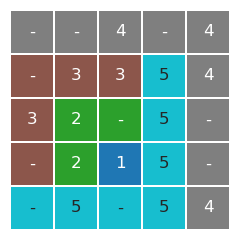

Took 3.3224 seconds
[3. 1. 1. 2. 2. 1.]
solution is 12
(array([0, 1, 2, 3, 4, 5]), array([10,  1,  2,  3,  4,  5], dtype=int64))
Connectivity:  True


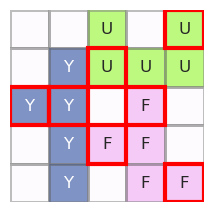

In [7]:
(soln,result_x,result_y,result_p) = solve(example)

setup done in 14.16 secs


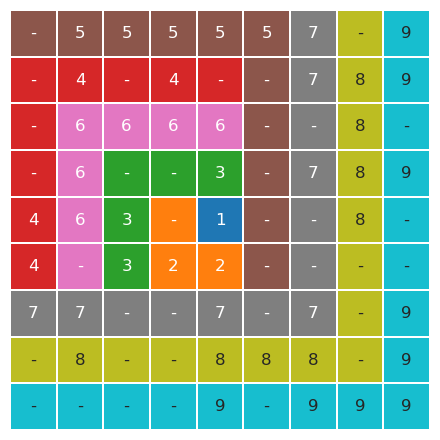

Took 231.1616 seconds
[ 4.  1.  1. 15.  1.  3.  1.  9.  1.]
solution is 1,620
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36,  1,  2,  3,  4,  5,  6,  7,  8,  9], dtype=int64))
Connectivity:  True


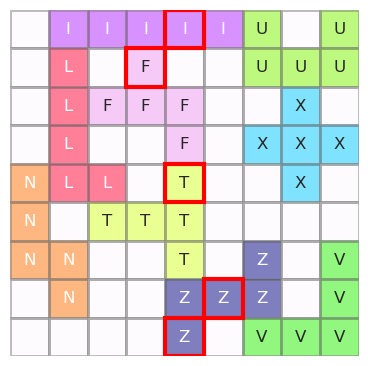

In [8]:
(soln,result_x,result_y,result_p) = solve(full)

In [9]:
for x in range(1,13):
    print(x,np.sum([n for (i,j),n in np.ndenumerate(soln) if result_p[i,j] == x]))

1 25
2 25
3 25
4 30
5 0.0
6 15
7 40
8 45
9 0.0
10 40
11 0.0
12 40


### Hooks 11
The above image shows the completed grid, first with numbers assigned and second with
pentomino letters labeled. The product of the empty regions is
1620
. Quick note that
1296 was the most common incorrect answer submitted, which is what you get if you slide
the I pentomino composed of 5’s to the left one square. Alas, that arrangement leaves the
filled squares in two disconnected regions so is not a valid arrangement.
Congrats to this month’s solvers!

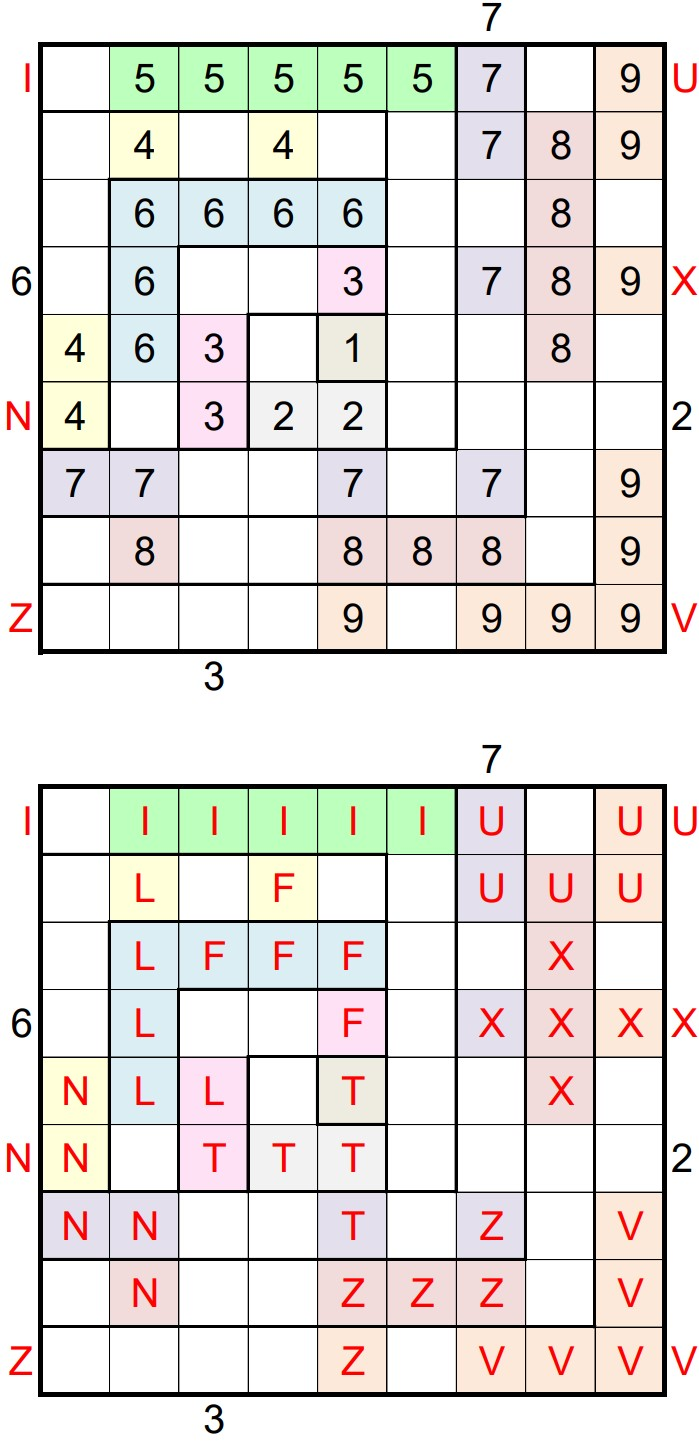

In [6]:
url='https://www.janestreet.com/puzzles/hooks-11-solution/'
res = requests.get(url)
soup = BeautifulSoup(res.content, 'html.parser')
y =[text.replace(">","greater than") for text in soup.body.stripped_strings]

#display([(i,j) for i,j in enumerate(y)])
display(Markdown("### "+y[13]+"\n"+"\n".join(y[16:20])))
display(Image('https://www.janestreet.com/puzzles/hooks-11-solution.jpg',width=300))

In [11]:
# example=np.array([[-1,-1, 4,-1, 4],
#                   [-1, 3, 3, 5, 4],
#                   [ 3, 2,-1, 5,-1],
#                   [-1, 2, 1, 5,-1],
#                   [-1, 5,-1, 5, 4]])


# full = np.array([  [-1,  5,  5,  5,  5,  5,  7, -1,  9],
#                    [-1,  4, -1,  4, -1, -1,  7,  8,  9],
#                    [-1,  6,  6,  6,  6, -1, -1,  8, -1],
#                    [-1,  6, -1, -1,  3, -1,  7,  8,  9],
#                    [ 4,  6,  3, -1,  1, -1, -1,  8, -1],
#                    [ 4, -1,  3,  2,  2, -1, -1, -1, -1],
#                    [ 7,  7, -1, -1,  7, -1,  7, -1,  9],
#                    [-1,  8, -1, -1,  8,  8,  8, -1,  9],
#                    [-1, -1, -1, -1,  9, -1,  9,  9,  9]])